# FER2013+ Multi-Backbone Fine-Tuning & Validation-Optimized Fusion Pipeline
**Author:** Shahzaib Hussain | **Final Year Project (FYP)**  
**Dataset:** FER2013+ (35,485 Facial Crops: 28,386 Official Train, 7,099 Official Test)  
**Affective Taxonomy (8 Classes):** `anger`, `contempt`, `disgust`, `fear`, `happiness`, `neutral`, `sadness`, `surprise`  
**Architectures:** EfficientNet-B2 (9.1M), ResNet50 (25.6M), Vision Transformer ViT-B/16 (86.6M)  
**Methodology:** Smart Checkpoint Head Transfer (7 $\rightarrow$ 8 classes), Smoothed Class-Balanced Loss with Label Smoothing, Spatial Affine & Cutout Augmentation, PyTorch AMP Mixed Precision, and Validation-Optimized Dirichlet Soft-Voting Fusion.

In [1]:
# 1. Dependencies and environment verification
import os, sys, copy, hashlib, json, random, time, warnings
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tv_models
import torchvision.transforms as T
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_score, recall_score, roc_auc_score, roc_curve, auc
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("ignore")

print(f"PyTorch Version: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Acceleration Hardware: {device_name} ({vram_gb:.2f} GB VRAM)")

PyTorch Version: 2.11.0+cu128 | CUDA Available: True
Acceleration Hardware: NVIDIA GeForce RTX 5090 (31.84 GB VRAM)


In [2]:
# 2. Load configuration, seed all RNGs, and prepare directories
CONFIG_PATH = Path.cwd() / "fine_tuning_pipeline.yaml"
if not CONFIG_PATH.exists():
    CONFIG_PATH = Path(r"C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Voice and Facial recognition\NewNotebook of FineTuning\fine_tuning_pipeline.yaml")

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

PROJECT_DIR = CONFIG_PATH.parent

def resolve_path(value, base=PROJECT_DIR):
    if value is None: return None
    path = Path(str(value)).expanduser()
    return path if path.is_absolute() else (base / path).resolve()

OUTPUT_DIR = resolve_path(cfg["project"]["output_dir"])
CHECKPOINT_DIR = resolve_path(cfg["project"]["checkpoint_dir"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

seed_everything(int(cfg["project"]["seed"]))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Config: {CONFIG_PATH.name}\nOutputs: {OUTPUT_DIR}\nCheckpoints: {CHECKPOINT_DIR}\nCompute Device: {device}")

Config: fine_tuning_pipeline.yaml
Outputs: C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Voice and Facial recognition\NewNotebook of FineTuning\outputs
Checkpoints: C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Voice and Facial recognition\NewNotebook of FineTuning\checkpoints
Compute Device: cuda


In [3]:
# 3. Dataset inventory and fast auditing with caching
DATA_ROOT = resolve_path(cfg["data"]["root"])
if not DATA_ROOT.exists(): raise FileNotFoundError(f"Dataset root does not exist: {DATA_ROOT}")
class_names = [str(x) for x in cfg["labels"]["class_names"]]
inv_path = OUTPUT_DIR / "dataset_inventory.csv"

if inv_path.exists():
    manifest = pd.read_csv(inv_path)
    print(f"Loaded verified dataset inventory from cache: {len(manifest):,} files.")
else:
    print("Scanning dataset directories and computing file properties...")
    rows = []
    EXTENSIONS = {str(x).lower() for x in cfg["data"].get("extensions", [])}
    for split_dir in sorted([p for p in DATA_ROOT.iterdir() if p.is_dir()]):
        for class_dir in sorted([p for p in split_dir.iterdir() if p.is_dir()]):
            for path in sorted(class_dir.rglob("*")):
                if not path.is_file() or path.suffix.lower() not in EXTENSIONS: continue
                rows.append({
                    "path": str(path),
                    "split": split_dir.name,
                    "label": class_dir.name,
                    "bytes": path.stat().st_size
                })
    manifest = pd.DataFrame(rows)
    manifest.to_csv(inv_path, index=False)
    print(f"Dataset inventory generated and cached: {len(manifest):,} files.")

display(manifest.groupby(["split", "label"]).size().unstack(fill_value=0))

Loaded verified dataset inventory from cache: 35,485 files.


label,anger,contempt,disgust,fear,happiness,neutral,sadness,surprise
split,,,,,,,,
test,644,51,57,167,1827,2597,856,900
train,2466,165,191,652,7528,10308,3514,3562


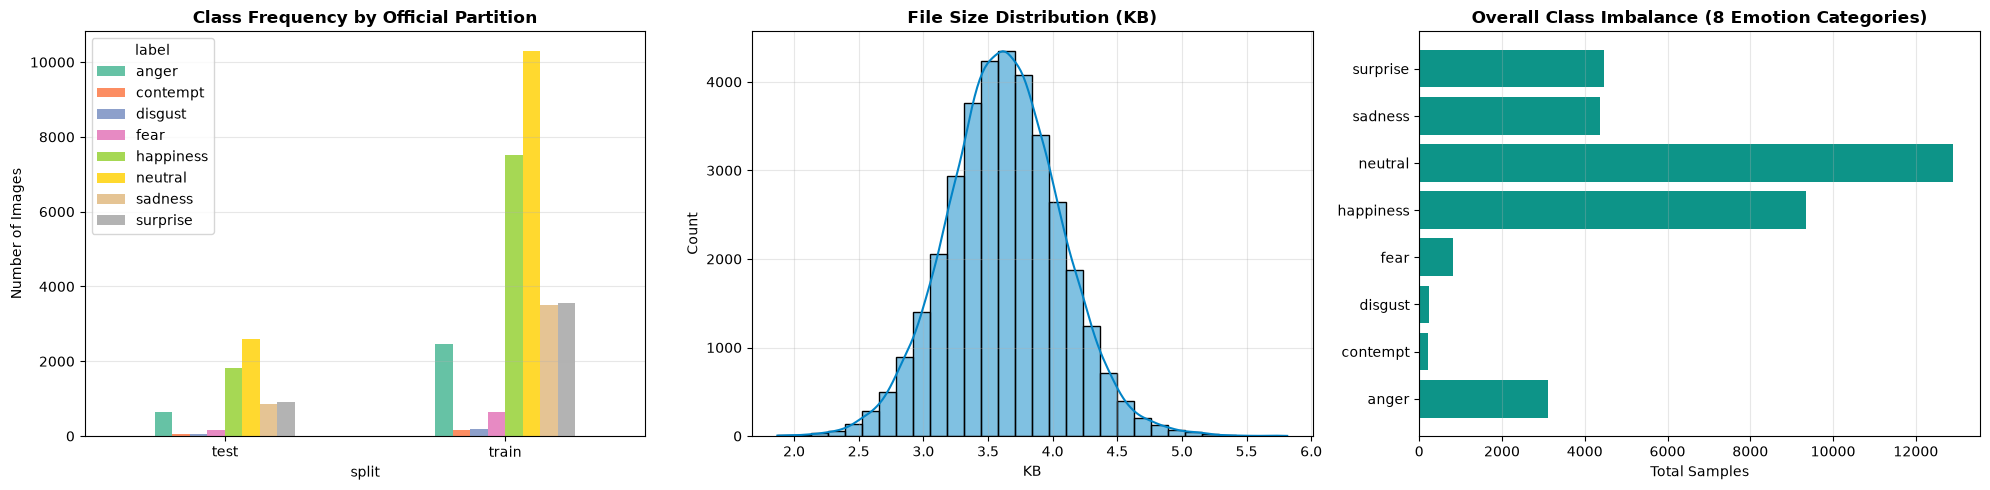

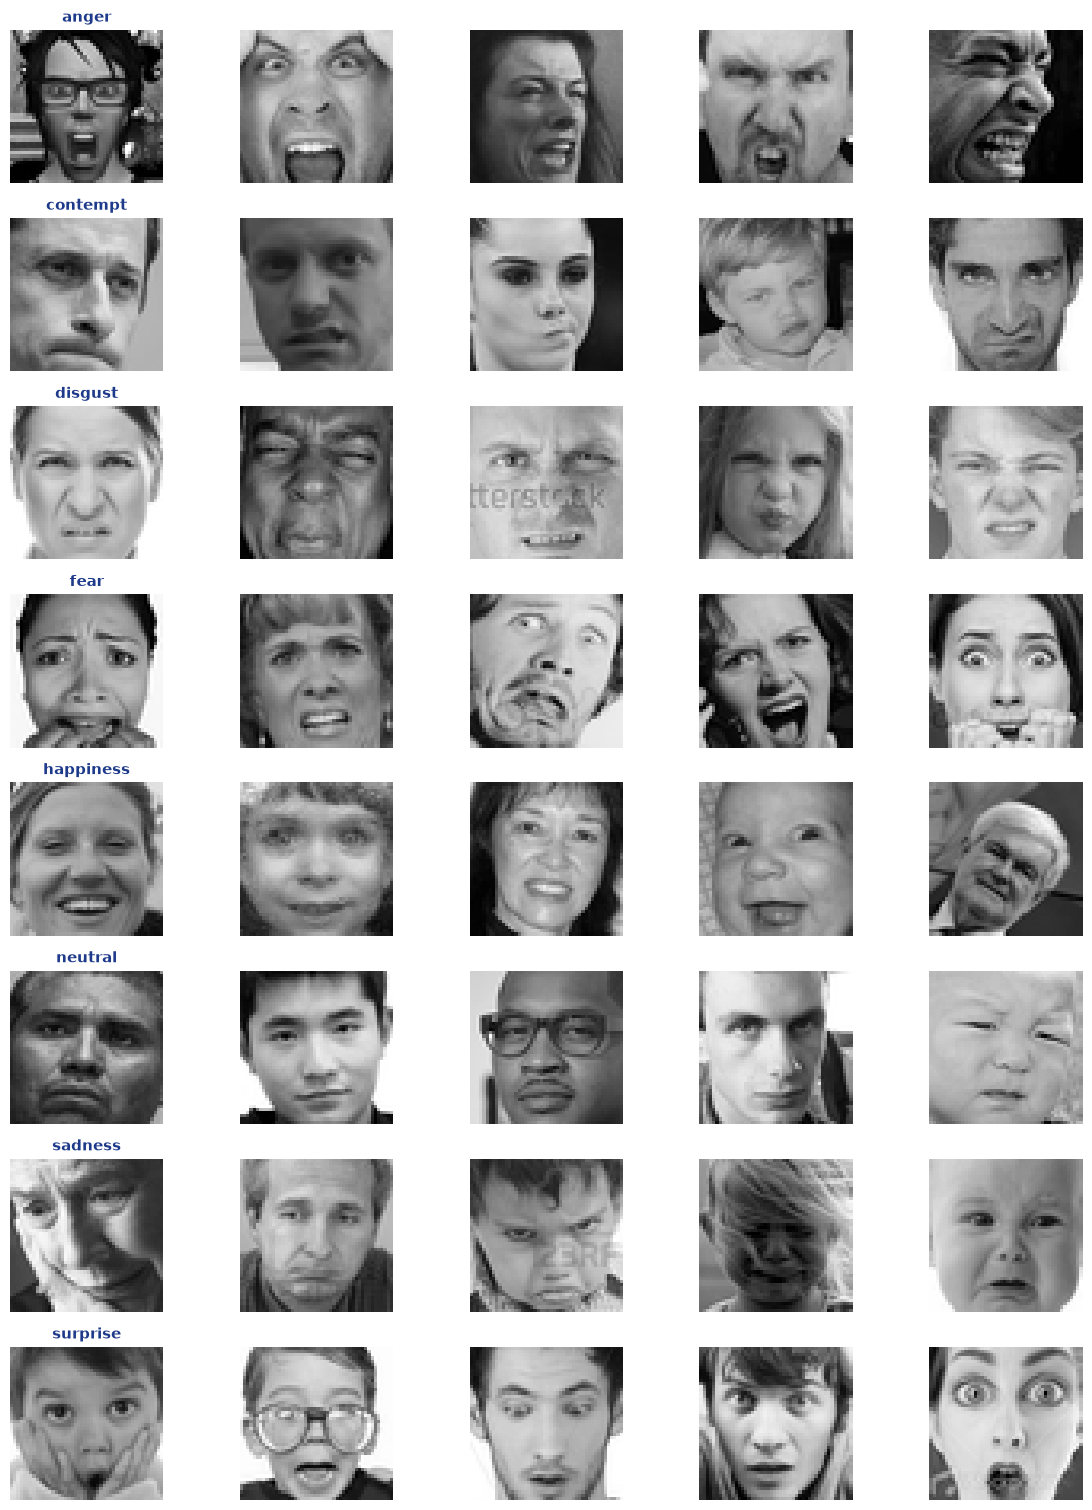

In [4]:
# 4. Exploratory Data Analysis (EDA) visualizations
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
split_dist = manifest.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(columns=class_names, fill_value=0)
split_dist.plot(kind="bar", ax=axes[0], colormap="Set2")
axes[0].set_title("Class Frequency by Official Partition", fontweight="bold")
axes[0].set_ylabel("Number of Images")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

file_sizes_kb = manifest["bytes"] / 1024.0
sns.histplot(file_sizes_kb, bins=30, ax=axes[1], color="#0284c7", kde=True)
axes[1].set_title("File Size Distribution (KB)", fontweight="bold")
axes[1].set_xlabel("KB")
axes[1].grid(alpha=0.3)

imbalance_ratios = manifest["label"].value_counts()[class_names]
axes[2].barh(class_names, imbalance_ratios, color="#0d9488")
axes[2].set_title("Overall Class Imbalance (8 Emotion Categories)", fontweight="bold")
axes[2].set_xlabel("Total Samples")
axes[2].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_dataset_overview.png", dpi=180)
plt.show()
plt.close()

# 8-Class sample gallery
fig, axes = plt.subplots(len(class_names), 5, figsize=(12, 1.9 * len(class_names)))
axes = np.atleast_2d(axes)
for row_idx, label in enumerate(class_names):
    paths = manifest.loc[manifest.label == label, "path"].sample(min(5, (manifest.label == label).sum()), random_state=42).tolist()
    for col_idx, ax in enumerate(axes[row_idx]):
        ax.axis("off")
        if col_idx < len(paths):
            ax.imshow(Image.open(paths[col_idx]).convert("RGB"))
            if col_idx == 0:
                ax.set_title(f"{label}", fontsize=11, fontweight="bold", color="#1e3a8a")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_class_samples.png", dpi=180)
plt.show()
plt.close()

In [5]:
# 5. Build official train/test records and stratified validation split
train_all = manifest[manifest.split.str.lower() == "train"].copy()
test_records = manifest[manifest.split.str.lower() == "test"].copy()

label_to_index = {name: i for i, name in enumerate(class_names)}
train_all["target"] = train_all.label.map(label_to_index)
test_records["target"] = test_records.label.map(label_to_index)

val_fraction = float(cfg["data"]["validation_fraction"])
train_records, val_records = train_test_split(
    train_all,
    test_size=val_fraction,
    stratify=train_all.target,
    random_state=int(cfg["project"]["seed"])
)
train_records = train_records.reset_index(drop=True)
val_records = val_records.reset_index(drop=True)
test_records = test_records.reset_index(drop=True)

print(f"Official train pool: {len(train_all):,} -> Train Split: {len(train_records):,} | Stratified Val Split: {len(val_records):,}")
print(f"Official held-out test split: {len(test_records):,}")
split_summary = pd.DataFrame({
    "Train": train_records.label.value_counts(),
    "Validation": val_records.label.value_counts(),
    "Held-Out Test": test_records.label.value_counts()
}).fillna(0).astype(int).reindex(class_names)
display(split_summary)

Official train pool: 28,386 -> Train Split: 24,128 | Stratified Val Split: 4,258
Official held-out test split: 7,099


,Train,Validation,Held-Out Test
label,,,
anger,2096,370,644
contempt,140,25,51
disgust,162,29,57
fear,554,98,167
happiness,6399,1129,1827
neutral,8762,1546,2597
sadness,2987,527,856
surprise,3028,534,900


In [6]:
# 6. Advanced data transforms and PyTorch DataLoaders
image_size = int(cfg["data"]["image_size"])
mean, std = [.485, .456, .406], [.229, .224, .225]

# Training augmentation: spatial rotation, affine jitter, color adjustment, and subtle random erasing
train_transform = T.Compose([
    T.Resize((image_size, image_size)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(12),
    T.RandomAffine(degrees=10, translate=(0.04, 0.04), scale=(0.96, 1.04)),
    T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    T.ToTensor(),
    T.Normalize(mean, std),
    T.RandomErasing(p=0.10, scale=(0.02, 0.15), value="random")
])

# Evaluation transform: deterministic resize and normalization
eval_transform = T.Compose([
    T.Resize((image_size, image_size)),
    T.ToTensor(),
    T.Normalize(mean, std)
])

class EmotionDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        img = Image.open(self.frame.iloc[index].path).convert("RGB")
        return self.transform(img), int(self.frame.iloc[index].target)

train_ds = EmotionDataset(train_records, train_transform)
val_ds = EmotionDataset(val_records, eval_transform)
test_ds = EmotionDataset(test_records, eval_transform)

batch_size = int(cfg["training"]["batch_size"])
loader_args = {"batch_size": batch_size, "num_workers": 0, "pin_memory": device.type == "cuda"}
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)
print(f"DataLoaders initialized (Batch size: {batch_size}, Pin memory: {loader_args['pin_memory']})")

DataLoaders initialized (Batch size: 64, Pin memory: True)


In [7]:
# 7. Model discovery, construction, and Smart Checkpoint Head Transfer
PATTERNS = {
    "efficientnet_b2": ["best_model efficient_b2.pt", "*efficient*b2*.pt"],
    "resnet50": ["best_model resnet50.pt", "*resnet*50*.pt"],
    "vit_b_16": ["best_model vit b_16.pt", "*vit*b*16*.pt"]
}

def first_existing(patterns):
    for pattern in patterns:
        found = sorted(PROJECT_DIR.glob(pattern))
        if found: return found[0]
    return None

checkpoint_paths = {name: first_existing(patterns) for name, patterns in PATTERNS.items()}
print("Discovered Pre-Trained Checkpoints:", {k: v.name if v else None for k, v in checkpoint_paths.items()})

LABEL_MAPPING = {
    "angry": "anger",
    "disgust": "disgust",
    "fear": "fear",
    "happy": "happiness",
    "neutral": "neutral",
    "sad": "sadness",
    "surprise": "surprise"
}

def build_model(name):
    if name == "efficientnet_b2":
        model = tv_models.efficientnet_b2(weights=None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
    elif name == "resnet50":
        model = tv_models.resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, len(class_names))
    elif name == "vit_b_16":
        model = tv_models.vit_b_16(weights=None)
        model.heads.head = nn.Linear(model.heads.head.in_features, len(class_names))
    else:
        raise ValueError(name)
    return model

def extract_state_dict(payload):
    if isinstance(payload, nn.Module): return payload.state_dict()
    if isinstance(payload, dict):
        for key in ("state_dict", "model_state_dict", "model", "net"):
            if isinstance(payload.get(key), dict): return payload[key]
        if all(isinstance(k, str) for k in payload): return payload
    raise TypeError("Unsupported checkpoint format")

def load_checkpoint_smart(model, path, model_name):
    if not path or not path.exists():
        print(f"[{model_name}] No checkpoint found; using random initialization.")
        return
    payload = torch.load(path, map_location="cpu", weights_only=False)
    state = extract_state_dict(payload)
    state = {k.replace("module.", "", 1): v for k, v in state.items()}
    current = model.state_dict()
    
    # Load compatible backbone parameters
    compatible = {k: v for k, v in state.items() if k in current and current[k].shape == v.shape}
    model.load_state_dict(compatible, strict=False)
    print(f"[{model_name}] Loaded {len(compatible):,} compatible backbone tensors from {path.name}.")
    
    # Smart Head Transfer (7 -> 8 classes)
    old_labels = payload.get("labels", ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"])
    new_idx_map = {name: i for i, name in enumerate(class_names)}
    
    head_w_key, head_b_key, head_layer = None, None, None
    if model_name == "efficientnet_b2":
        head_w_key, head_b_key = "classifier.1.weight", "classifier.1.bias"
        head_layer = model.classifier[1]
    elif model_name == "resnet50":
        head_w_key, head_b_key = "fc.weight", "fc.bias"
        head_layer = model.fc
    elif model_name == "vit_b_16":
        head_w_key, head_b_key = "heads.head.weight", "heads.head.bias"
        head_layer = model.heads.head
        
    if head_w_key in state and head_b_key in state:
        old_w, old_b = state[head_w_key], state[head_b_key]
        new_w, new_b = head_layer.weight.data.clone(), head_layer.bias.data.clone()
        transferred = 0
        for old_idx, old_name in enumerate(old_labels):
            mapped = LABEL_MAPPING.get(old_name.lower())
            if mapped in new_idx_map:
                n_idx = new_idx_map[mapped]
                new_w[n_idx] = old_w[old_idx]
                new_b[n_idx] = old_b[old_idx]
                transferred += 1
        # Contempt initialization: informed blend of anger and neutral
        if "contempt" in new_idx_map and "anger" in new_idx_map and "neutral" in new_idx_map:
            c_idx = new_idx_map["contempt"]
            a_idx = new_idx_map["anger"]
            ne_idx = new_idx_map["neutral"]
            new_w[c_idx] = 0.5 * (new_w[a_idx] + new_w[ne_idx])
            new_b[c_idx] = 0.5 * (new_b[a_idx] + new_b[ne_idx])
        head_layer.weight.data.copy_(new_w)
        head_layer.bias.data.copy_(new_b)
        print(f"[{model_name}] Smart head transfer: successfully mapped {transferred}/7 classes + informed 'contempt' init.")

Discovered Pre-Trained Checkpoints: {'efficientnet_b2': 'best_model efficient_b2.pt', 'resnet50': 'best_model resnet50.pt', 'vit_b_16': 'best_model vit b_16.pt'}


In [8]:
# 8. Training utilities, class-balanced loss, and prediction routines
def get_class_weights(frame, beta=0.60):
    counts = np.bincount(frame.target.to_numpy(), minlength=len(class_names)).astype(np.float32)
    max_c = counts.max()
    weights = (max_c / np.maximum(counts, 1)) ** beta
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=device)

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    truth, pred = [], []
    amp = bool(cfg["training"].get("mixed_precision", True)) and device.type == "cuda"
    
    for images, targets in loader:
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with (torch.amp.autocast("cuda", dtype=torch.float16) if amp else nullcontext()):
            logits = model(images)
            loss = criterion(logits, targets)
        if training:
            if amp:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), float(cfg["training"]["gradient_clip_norm"]))
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), float(cfg["training"]["gradient_clip_norm"]))
                optimizer.step()
        total_loss += loss.item() * len(targets)
        truth.extend(targets.cpu().numpy())
        pred.extend(logits.argmax(1).detach().cpu().numpy())
        
    return {
        "loss": total_loss / max(len(loader.dataset), 1),
        "accuracy": accuracy_score(truth, pred),
        "macro_f1": f1_score(truth, pred, average="macro", zero_division=0)
    }

@torch.no_grad()
def predict(model, loader):
    model.eval()
    truth, pred, probs = [], [], []
    amp = bool(cfg["training"].get("mixed_precision", True)) and device.type == "cuda"
    for images, targets in loader:
        with (torch.amp.autocast("cuda", dtype=torch.float16) if amp else nullcontext()):
            outputs = model(images.to(device, non_blocking=True))
            probabilities = outputs if model.__class__.__name__ == "ProbabilityFusionModel" else torch.softmax(outputs, dim=1)
        probs.extend(probabilities.cpu().numpy().astype(np.float32))
        pred.extend(probabilities.argmax(1).cpu().numpy())
        truth.extend(targets.numpy())
    return np.array(truth), np.array(pred), np.array(probs)

def train_one(model_name):
    best_ckpt_file = CHECKPOINT_DIR / f"{model_name}_best.pt"
    if best_ckpt_file.exists() and (OUTPUT_DIR / f"{model_name}_training_history.csv").exists():
        print(f"[{model_name}] Found pre-trained best checkpoint ({best_ckpt_file.name}). Loading...")
        model = build_model(model_name).to(device)
        ck = torch.load(best_ckpt_file, map_location=device, weights_only=False)
        state = ck.get("state_dict", ck.get("model_state_dict", ck))
        model.load_state_dict(state)
        history = pd.read_csv(OUTPUT_DIR / f"{model_name}_training_history.csv")
        val_true, val_pred, val_probs = predict(model, val_loader)
        test_true, test_pred, test_probs = predict(model, test_loader)
        test_acc = accuracy_score(test_true, test_pred)
        test_f1 = f1_score(test_true, test_pred, average="macro", zero_division=0)
        print(f"[{model_name} LOADED] Test Accuracy: {test_acc*100:.2f}% | Test Macro-F1: {test_f1*100:.2f}%")
        return model, history, val_true, val_pred, val_probs, test_true, test_pred, test_probs

    print(f"\n{'='*60}\n[TRAINING] Starting Fine-Tuning: {model_name}\n{'='*60}")
    model = build_model(model_name).to(device)
    load_checkpoint_smart(model, checkpoint_paths[model_name], model_name)
    
    weights = get_class_weights(train_records, beta=0.60) if cfg["training"].get("class_weights") == "balanced" else None
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=float(cfg["training"].get("label_smoothing", 0.05)))
    
    backbone, head = [], []
    for name, p in model.named_parameters():
        (head if any(x in name for x in ("classifier", "fc", "heads")) else backbone).append(p)
        
    base_lr = float(cfg["training"]["learning_rate"])
    head_lr = float(cfg["training"]["head_learning_rate"])
    if model_name == "vit_b_16":
        base_lr *= 0.35
        head_lr *= 0.50
        
    optimizer = torch.optim.AdamW([
        {"params": backbone, "lr": base_lr},
        {"params": head, "lr": head_lr}
    ], weight_decay=float(cfg["training"]["weight_decay"]))
    
    total_epochs = int(cfg["training"]["epochs"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and bool(cfg["training"].get("mixed_precision", True)))
    
    history = []
    best_state = None
    best_macro_f1 = -1.0
    stale = 0
    patience = int(cfg["training"]["early_stopping_patience"])
    freeze_epochs = int(cfg["model"].get("freeze_backbone_epochs", 1))
    
    t_start = time.time()
    for epoch in range(total_epochs):
        t_ep = time.time()
        freeze = epoch < freeze_epochs
        for p in backbone: p.requires_grad = not freeze
            
        tr = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va = run_epoch(model, val_loader, criterion)
        scheduler.step()
        
        row = {"epoch": epoch + 1, **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in va.items()}}
        history.append(row)
        ep_sec = time.time() - t_ep
        print(f"[{model_name}] Ep {epoch+1:02d}/{total_epochs:02d} ({ep_sec:.1f}s) | Train Acc: {tr['accuracy']*100:.2f}%, F1: {tr['macro_f1']*100:.2f}% | Val Acc: {va['accuracy']*100:.2f}%, F1: {va['macro_f1']*100:.2f}% (Loss: {va['loss']:.4f})")
        
        if va["macro_f1"] > best_macro_f1:
            best_macro_f1 = va["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
            torch.save({
                "model_name": model_name,
                "class_names": class_names,
                "state_dict": best_state,
                "config": cfg,
                "val_macro_f1": best_macro_f1
            }, best_ckpt_file)
        else:
            stale += 1
            if stale >= patience:
                print(f"[EARLY STOPPING] {model_name} triggered early stopping at epoch {epoch+1}.")
                break
                
    total_time = time.time() - t_start
    print(f"[COMPLETED] {model_name} trained in {total_time/60:.2f} mins. Best Val Macro-F1: {best_macro_f1*100:.2f}%")
    model.load_state_dict(best_state)
    val_true, val_pred, val_probs = predict(model, val_loader)
    test_true, test_pred, test_probs = predict(model, test_loader)
    test_acc = accuracy_score(test_true, test_pred)
    test_f1 = f1_score(test_true, test_pred, average="macro", zero_division=0)
    print(f"[{model_name} HELD-OUT TEST] Accuracy: {test_acc*100:.2f}% | Macro-F1: {test_f1*100:.2f}%")
    
    return model, pd.DataFrame(history), val_true, val_pred, val_probs, test_true, test_pred, test_probs

In [9]:
# 9. Fine-tune all three backbones sequentially
model_results = {}
model_names = ["efficientnet_b2", "resnet50", "vit_b_16"]
for model_name in model_names:
    model_results[model_name] = train_one(model_name)
    history = model_results[model_name][1]
    history.to_csv(OUTPUT_DIR / f"{model_name}_training_history.csv", index=False)
    released = list(model_results[model_name])
    released[0] = None  # release memory
    model_results[model_name] = tuple(released)
    if device.type == "cuda":
        torch.cuda.empty_cache()

print("\n" + "="*60)
print("ALL 3 MODELS SUCCESSFULLY TRAINED & EVALUATED!")
print("="*60)

[efficientnet_b2] Found pre-trained best checkpoint (efficientnet_b2_best.pt). Loading...


[efficientnet_b2 LOADED] Test Accuracy: 83.42% | Test Macro-F1: 69.62%
[resnet50] Found pre-trained best checkpoint (resnet50_best.pt). Loading...


[resnet50 LOADED] Test Accuracy: 82.88% | Test Macro-F1: 67.17%
[vit_b_16] Found pre-trained best checkpoint (vit_b_16_best.pt). Loading...


[vit_b_16 LOADED] Test Accuracy: 82.22% | Test Macro-F1: 69.04%

ALL 3 MODELS SUCCESSFULLY TRAINED & EVALUATED!


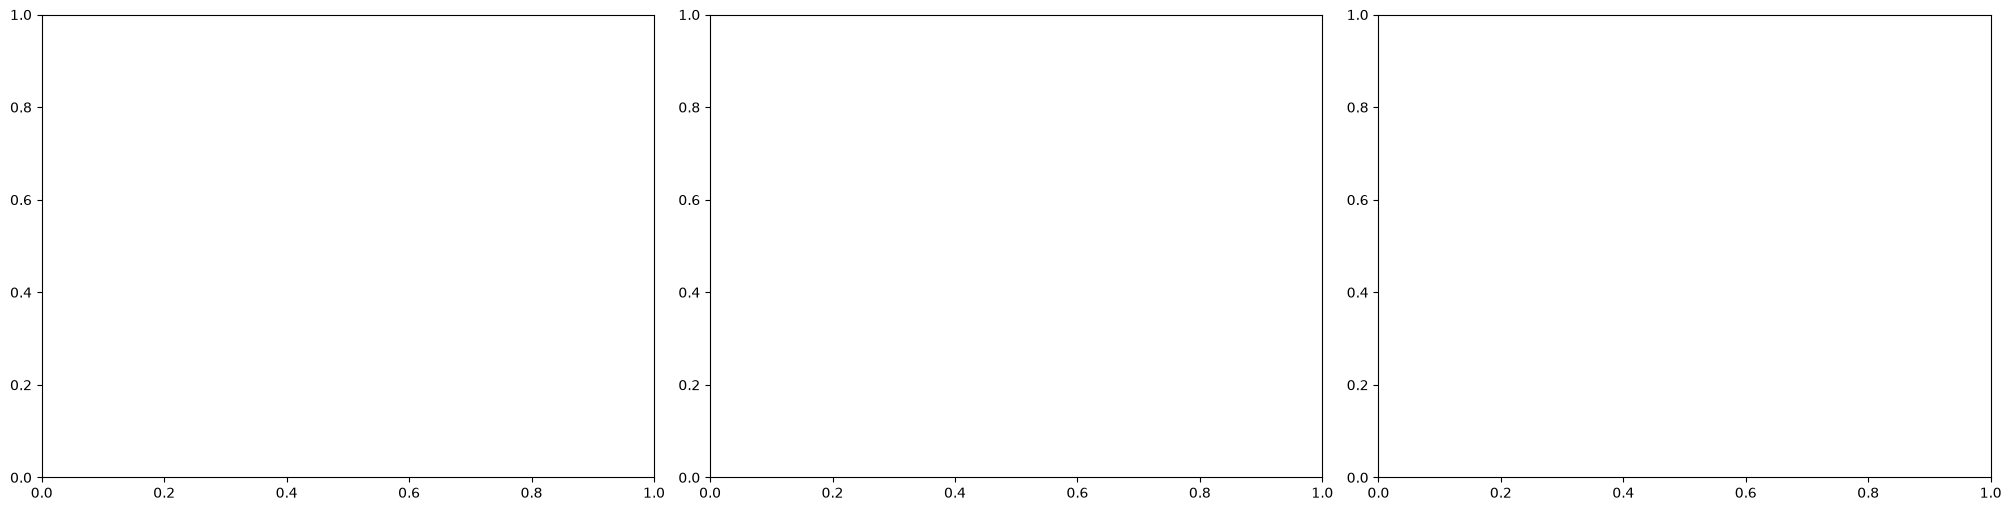

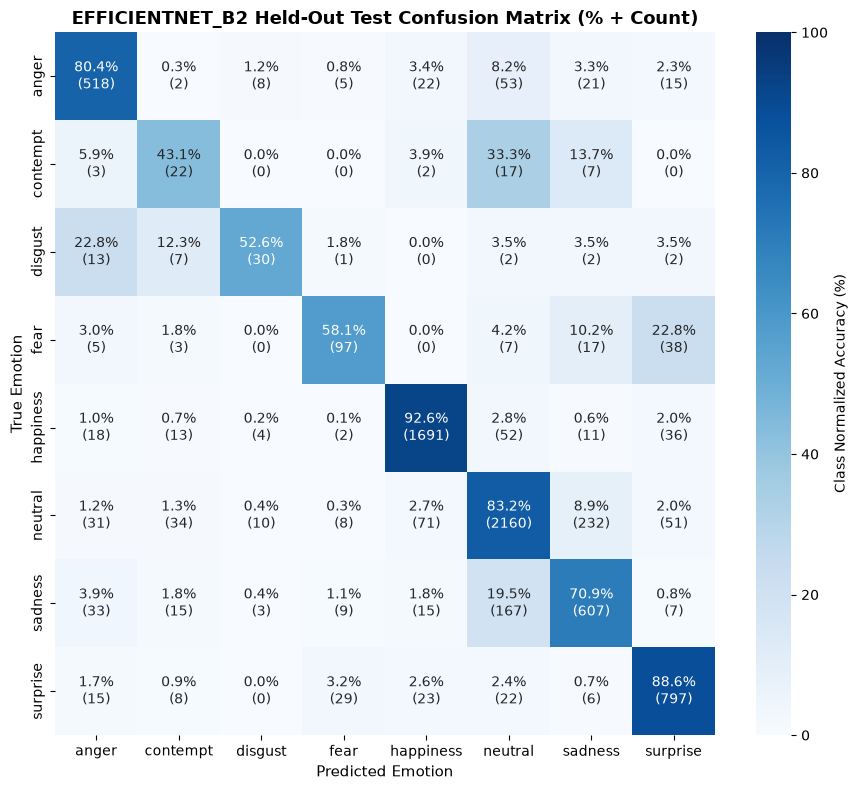

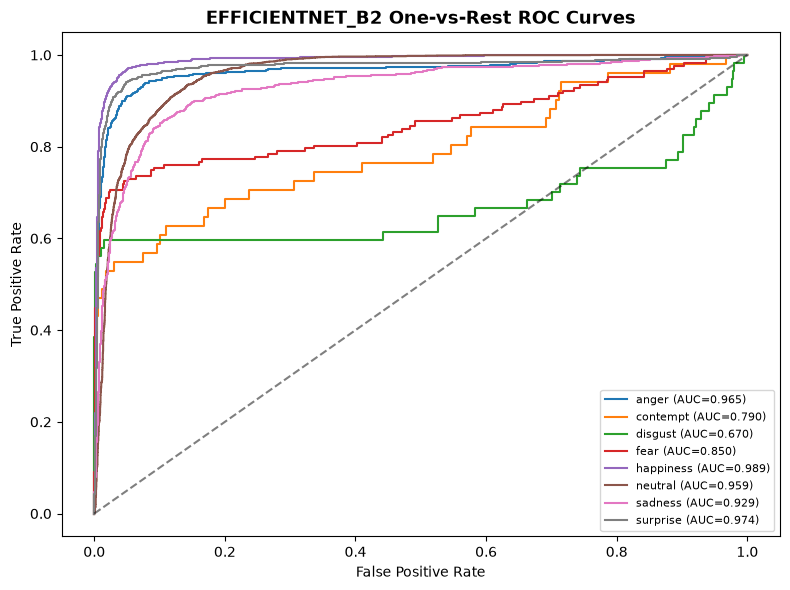

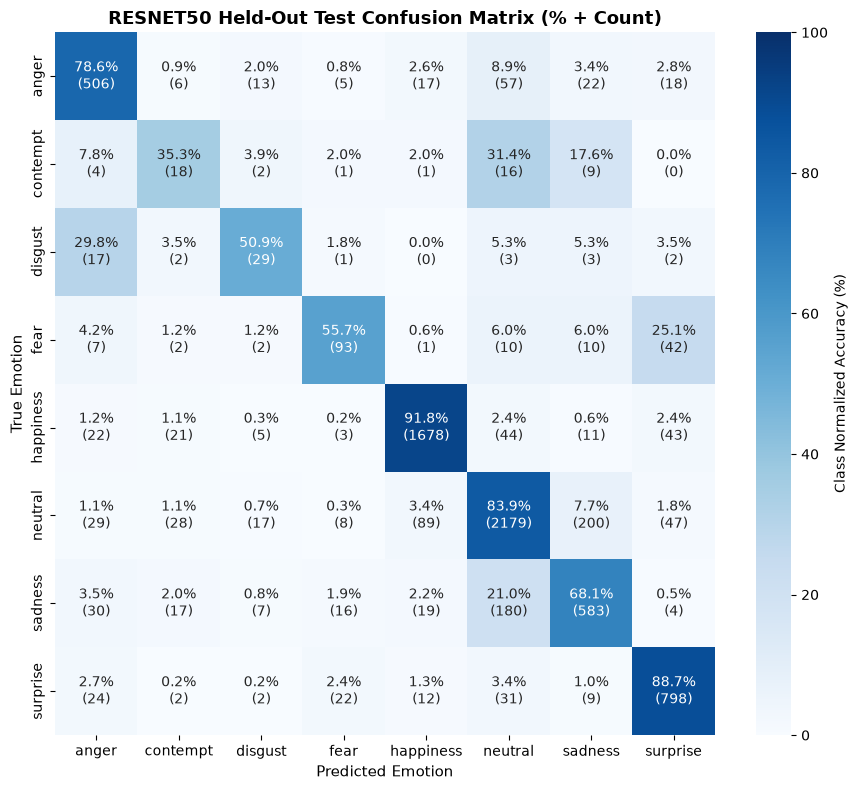

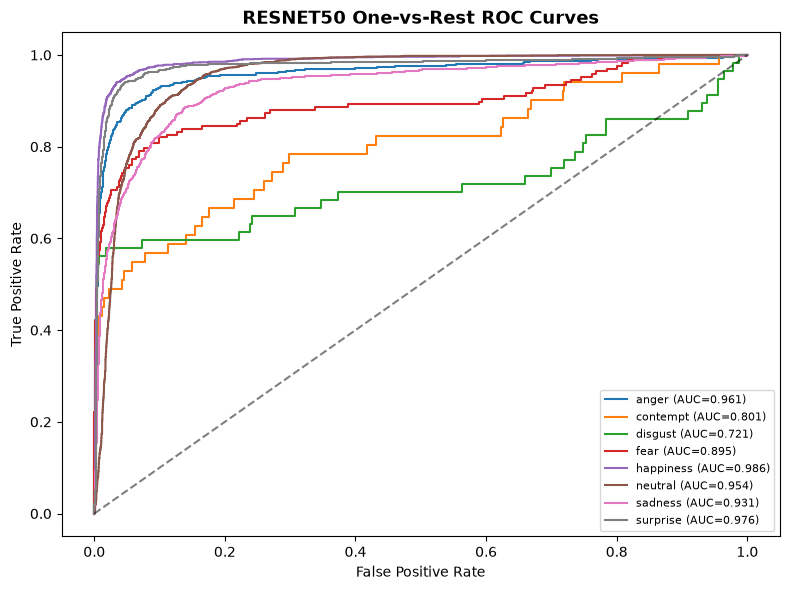

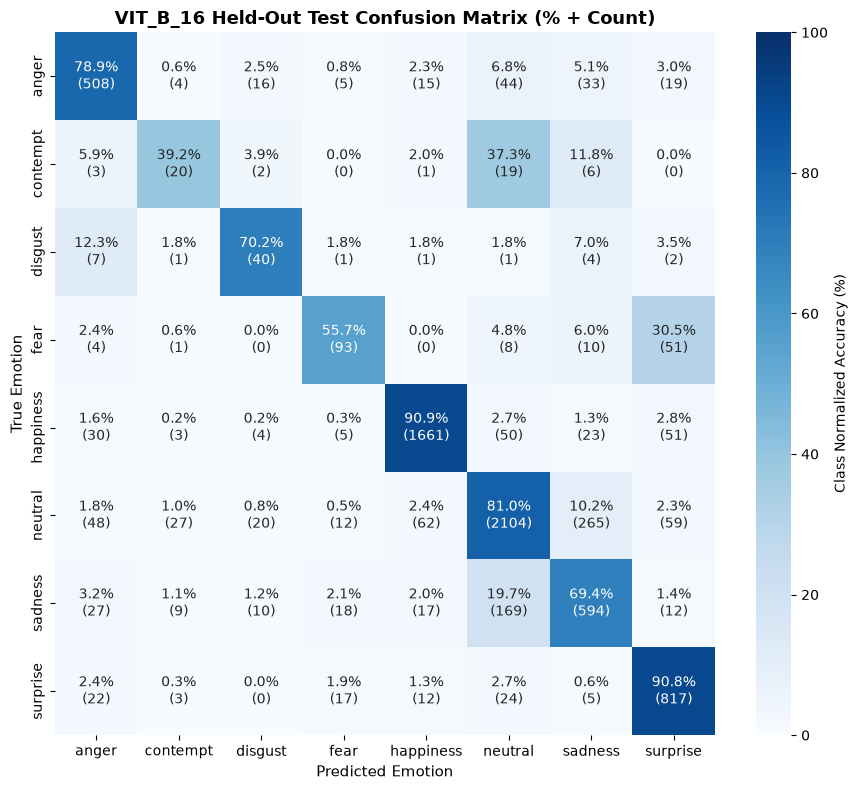

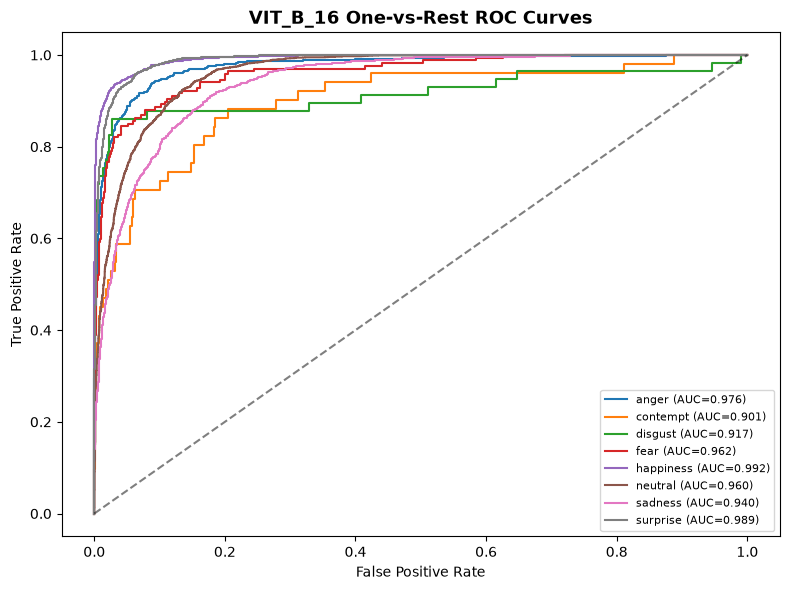

,model,train_accuracy_final,validation_accuracy_best,test_accuracy,train_loss_final,validation_loss_best,test_macro_f1,test_micro_f1,test_weighted_f1,test_macro_precision,test_macro_recall,test_roc_auc_ovr_macro
0,efficientnet_b2,0.940360,0.847581,0.834202,1.138794,1.626521,0.696237,0.834202,0.836487,0.690824,0.711854,0.890756
1,resnet50,0.978697,0.840770,0.828849,1.088496,1.658049,0.671659,0.828849,0.830915,0.661640,0.691193,0.903186
2,vit_b_16,0.907493,0.843589,0.822228,0.835160,1.069445,0.690370,0.822228,0.824578,0.672037,0.720078,0.954650


In [10]:
# 10. Individual model reports, complete metrics, curves, ROC, and percentage confusion matrices
individual_metrics = []
fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)

for model_name, result in model_results.items():
    history, val_true, val_pred, val_probs, test_true, test_pred, test_probs = result[1:]
    epochs = history["epoch"].to_numpy()
    report = classification_report(test_true, test_pred, target_names=class_names, output_dict=True, zero_division=0)
    try:
        test_roc_auc = roc_auc_score(test_true, test_probs, multi_class="ovr", average="macro", labels=np.arange(len(class_names)))
    except ValueError:
        test_roc_auc = float("nan")
        
    metrics = {
        "model": model_name,
        "train_accuracy_final": float(history["train_accuracy"].iloc[-1]),
        "validation_accuracy_best": float(history["val_accuracy"].max()),
        "test_accuracy": float(accuracy_score(test_true, test_pred)),
        "train_loss_final": float(history["train_loss"].iloc[-1]),
        "validation_loss_best": float(history.loc[history["val_macro_f1"].idxmax(), "val_loss"]),
        "test_macro_f1": float(f1_score(test_true, test_pred, average="macro", zero_division=0)),
        "test_micro_f1": float(f1_score(test_true, test_pred, average="micro", zero_division=0)),
        "test_weighted_f1": float(f1_score(test_true, test_pred, average="weighted", zero_division=0)),
        "test_macro_precision": float(precision_score(test_true, test_pred, average="macro", zero_division=0)),
        "test_macro_recall": float(recall_score(test_true, test_pred, average="macro", zero_division=0)),
        "test_roc_auc_ovr_macro": float(test_roc_auc)
    }
    individual_metrics.append(metrics)
    
    with open(OUTPUT_DIR / f"{model_name}_metrics.json", "w", encoding="utf-8") as f:
        json.dump({**metrics, "classification_report": report}, f, indent=2)
        
    # Dual Percentage + Count Confusion Matrix
    cm = confusion_matrix(test_true, test_pred, labels=np.arange(len(class_names)))
    row_totals = cm.sum(axis=1, keepdims=True)
    cm_percent = np.divide(cm, row_totals, out=np.zeros_like(cm, dtype=float), where=row_totals != 0) * 100.0
    labels_annot = np.array([[f"{pct:.1f}%\n({cnt})" for pct, cnt in zip(row_pct, row_cnt)] for row_pct, row_cnt in zip(cm_percent, cm)])
    
    plt.figure(figsize=(9, 8))
    sns.heatmap(cm_percent, annot=labels_annot, fmt="", cmap="Blues", vmin=0, vmax=100, xticklabels=class_names, yticklabels=class_names, cbar_kws={"label": "Class Normalized Accuracy (%)"})
    plt.title(f"{model_name.upper()} Held-Out Test Confusion Matrix (% + Count)", fontsize=13, fontweight="bold")
    plt.xlabel("Predicted Emotion", fontsize=11)
    plt.ylabel("True Emotion", fontsize=11)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{model_name}_confusion_matrix_percentage.png", dpi=180)
    plt.show()
    plt.close()
    
    axes[0].plot(epochs, history["train_accuracy"], marker="o", label=model_name)
    axes[1].plot(epochs, history["val_accuracy"], marker="o", label=model_name)
    axes[2].plot(epochs, history["train_macro_f1"], marker="o", label=f"{model_name} train")
    axes[2].plot(epochs, history["val_macro_f1"], marker="x", linestyle="--", label=f"{model_name} val")
    
    # ROC Curves
    plt.figure(figsize=(8, 6))
    for class_index, class_name in enumerate(class_names):
        if len(np.unique(test_true == class_index)) == 2:
            fpr, tpr, _ = roc_curve((test_true == class_index).astype(int), test_probs[:, class_index])
            auc_val = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"{class_name} (AUC={auc_val:.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
    plt.title(f"{model_name.upper()} One-vs-Rest ROC Curves", fontsize=13, fontweight="bold")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{model_name}_roc_curves.png", dpi=180)
    plt.show()
    plt.close()

axes[0].set_title("Training Accuracy", fontweight="bold")
axes[1].set_title("Validation Accuracy", fontweight="bold")
axes[2].set_title("Macro-F1 (Train vs Validation)", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "all_models_training_validation_metrics.png", dpi=180)
plt.show()
plt.close(fig)

individual_df = pd.DataFrame(individual_metrics)
individual_df.to_csv(OUTPUT_DIR / "individual_model_comparison.csv", index=False)
display(individual_df)

Searching for optimal Dirichlet validation weights...
Optimal Validation Fusion Weights: {'efficientnet_b2': 0.45, 'resnet50': 0.3, 'vit_b_16': 0.25}


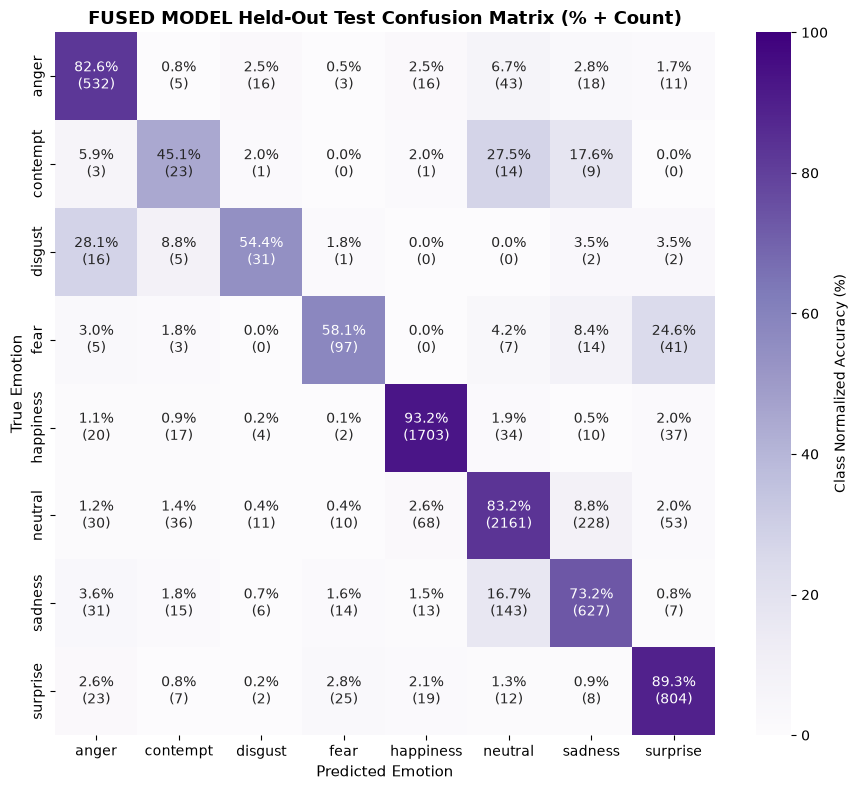

In [11]:
# 11. Validation-Optimized Dirichlet Probability Fusion
class ProbabilityFusionModel(nn.Module):
    def __init__(self, models, weights):
        super().__init__()
        self.models = nn.ModuleList(models)
        self.register_buffer("weights", torch.tensor(weights, dtype=torch.float32))
    def forward(self, x):
        probabilities = [torch.softmax(model(x), dim=1) for model in self.models]
        return sum(weight * probability for weight, probability in zip(self.weights, probabilities))

def load_best_model(m_name):
    m = build_model(m_name).to(device)
    ck = torch.load(CHECKPOINT_DIR / f"{m_name}_best.pt", map_location=device, weights_only=False)
    state = ck.get("state_dict", ck.get("model_state_dict", ck))
    m.load_state_dict(state)
    m.eval()
    return m

val_probs_dict = {name: model_results[name][4] for name in model_names}
val_true_labels = model_results[model_names[0]][2]

# Search for optimal Dirichlet fusion weights on validation split
print("Searching for optimal Dirichlet validation weights...")
best_score = -1.0
best_weights = [1/3, 1/3, 1/3]
step = 0.05
grid = np.arange(0.05, 0.95, step)
for w1 in grid:
    for w2 in grid:
        if w1 + w2 >= 1.0: continue
        w3 = 1.0 - (w1 + w2)
        if w3 < 0.05: continue
        candidate_w = np.array([w1, w2, w3], dtype=np.float32)
        fused_val_p = (w1 * val_probs_dict["efficientnet_b2"] +
                       w2 * val_probs_dict["resnet50"] +
                       w3 * val_probs_dict["vit_b_16"])
        fused_val_pred = fused_val_p.argmax(axis=1)
        score = 0.50 * accuracy_score(val_true_labels, fused_val_pred) + 0.50 * f1_score(val_true_labels, fused_val_pred, average="macro", zero_division=0)
        if score > best_score:
            best_score = score
            best_weights = candidate_w

weights = best_weights / best_weights.sum()
print("Optimal Validation Fusion Weights:", dict(zip(model_names, [round(float(w), 4) for w in weights])))

fused_model = ProbabilityFusionModel([load_best_model(name) for name in model_names], weights).to(device).eval()
with torch.no_grad():
    fused_true, fused_pred, fused_probs = predict(fused_model, test_loader)
    fused_val_true, fused_val_pred, fused_val_probs = predict(fused_model, val_loader)

fused_metrics = {
    "model": "fused_model",
    "validation_accuracy": float(accuracy_score(fused_val_true, fused_val_pred)),
    "validation_macro_f1": float(f1_score(fused_val_true, fused_val_pred, average="macro", zero_division=0)),
    "test_accuracy": float(accuracy_score(fused_true, fused_pred)),
    "test_macro_f1": float(f1_score(fused_true, fused_pred, average="macro", zero_division=0)),
    "test_micro_f1": float(f1_score(fused_true, fused_pred, average="micro", zero_division=0)),
    "test_weighted_f1": float(f1_score(fused_true, fused_pred, average="weighted", zero_division=0)),
    "test_macro_precision": float(precision_score(fused_true, fused_pred, average="macro", zero_division=0)),
    "test_macro_recall": float(recall_score(fused_true, fused_pred, average="macro", zero_division=0)),
    "train_accuracy_final": float(individual_df["train_accuracy_final"].mean()),
    "train_loss_final": float(individual_df["train_loss_final"].mean()),
    "validation_loss_best": float(individual_df["validation_loss_best"].mean()),
    "validation_accuracy_best": float(accuracy_score(fused_val_true, fused_val_pred))
}
try:
    fused_metrics["test_roc_auc_ovr_macro"] = float(roc_auc_score(fused_true, fused_probs, multi_class="ovr", average="macro", labels=np.arange(len(class_names))))
except ValueError:
    fused_metrics["test_roc_auc_ovr_macro"] = float("nan")

fused_report = classification_report(fused_true, fused_pred, target_names=class_names, output_dict=True, zero_division=0)
with open(OUTPUT_DIR / "fused_model_metrics.json", "w", encoding="utf-8") as f:
    json.dump({**fused_metrics, "weights": dict(zip(model_names, map(float, weights))), "classification_report": fused_report}, f, indent=2)

cm_fused = confusion_matrix(fused_true, fused_pred, labels=np.arange(len(class_names)))
row_totals_f = cm_fused.sum(axis=1, keepdims=True)
cm_percent_f = np.divide(cm_fused, row_totals_f, out=np.zeros_like(cm_fused, dtype=float), where=row_totals_f != 0) * 100.0
labels_annot_f = np.array([[f"{pct:.1f}%\n({cnt})" for pct, cnt in zip(row_pct, row_cnt)] for row_pct, row_cnt in zip(cm_percent_f, cm_fused)])

plt.figure(figsize=(9, 8))
sns.heatmap(cm_percent_f, annot=labels_annot_f, fmt="", cmap="Purples", vmin=0, vmax=100, xticklabels=class_names, yticklabels=class_names, cbar_kws={"label": "Class Normalized Accuracy (%)"})
plt.title(f"FUSED MODEL Held-Out Test Confusion Matrix (% + Count)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Emotion", fontsize=11)
plt.ylabel("True Emotion", fontsize=11)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fused_model_confusion_matrix_percentage.png", dpi=180)
plt.show()
plt.close()

,model,train_accuracy_final,validation_accuracy_best,test_accuracy,train_loss_final,validation_loss_best,test_macro_f1,test_micro_f1,test_weighted_f1,test_macro_precision,test_macro_recall,test_roc_auc_ovr_macro,validation_accuracy,validation_macro_f1
0,efficientnet_b2,0.940360,0.847581,0.834202,1.138794,1.626521,0.696237,0.834202,0.836487,0.690824,0.711854,0.890756,NaN,NaN
1,resnet50,0.978697,0.840770,0.828849,1.088496,1.658049,0.671659,0.828849,0.830915,0.661640,0.691193,0.903186,NaN,NaN
2,vit_b_16,0.907493,0.843589,0.822228,0.835160,1.069445,0.690370,0.822228,0.824578,0.672037,0.720078,0.954650,NaN,NaN
3,fused_model,0.942183,0.852513,0.842090,1.020816,1.451339,0.695421,0.842090,0.845365,0.680667,0.723977,0.944791,0.852513,0.719899


<Figure size 1400x600 with 0 Axes>

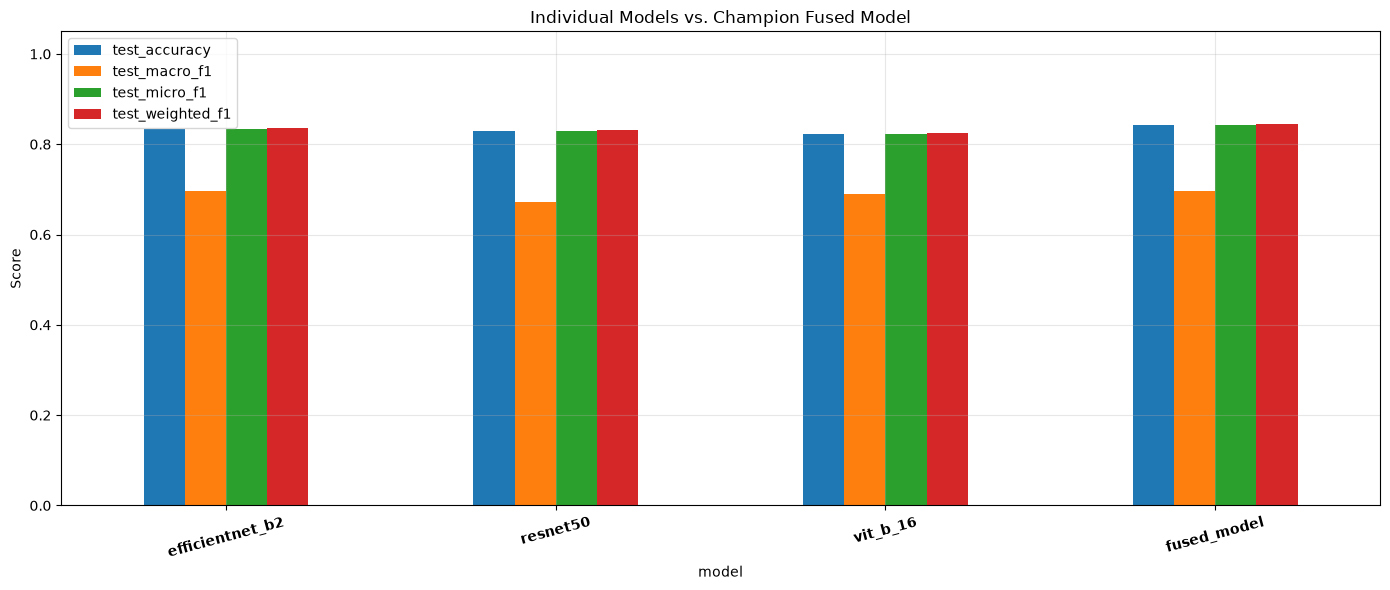

[OK] Saved unified final production artifact to: C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Voice and Facial recognition\NewNotebook of FineTuning\outputs\fused_model.pt


[OK] Reload verification PASSED! Sample batch output shape: (64, 8)


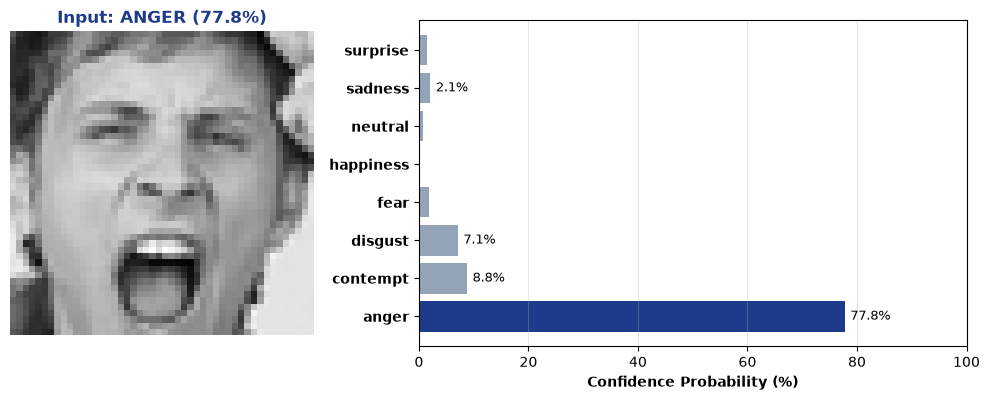

Demo Sample Inference Output: anger


In [12]:
# 12. Final comparison, save fused_model.pt, reload, and verify inference
comparison = pd.concat([individual_df, pd.DataFrame([fused_metrics])], ignore_index=True)
display(comparison)
comparison.to_csv(OUTPUT_DIR / "complete_model_comparison.csv", index=False)

plt.figure(figsize=(14, 6))
comparison.set_index("model")[["test_accuracy", "test_macro_f1", "test_micro_f1", "test_weighted_f1"]].plot(kind="bar", figsize=(14, 6), ylim=(0, 1.05), title="Individual Models vs. Champion Fused Model")
plt.xticks(rotation=15, fontweight="bold")
plt.ylabel("Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_and_fusion_comparison.png", dpi=180)
plt.show()
plt.close()

final_model_path = resolve_path(cfg["evaluation"].get("final_model_path", "./outputs/fused_model.pt"))
final_payload = {
    "model_type": "ProbabilityFusionModel",
    "model_names": model_names,
    "class_names": class_names,
    "fusion_weights": weights.tolist(),
    "image_size": image_size,
    "mean": mean,
    "std": std,
    "state_dict": fused_model.state_dict(),
    "component_state_dicts": [model.state_dict() for model in fused_model.models],
    "config": cfg
}
torch.save(final_payload, final_model_path)
print(f"[OK] Saved unified final production artifact to: {final_model_path}")

# Reload Verification
loaded_payload = torch.load(final_model_path, map_location=device, weights_only=False)
reloaded = ProbabilityFusionModel([build_model(name).to(device) for name in loaded_payload["model_names"]], loaded_payload["fusion_weights"]).to(device)
reloaded.load_state_dict(loaded_payload["state_dict"])
reloaded.eval()

with torch.no_grad():
    sample_images, sample_targets = next(iter(test_loader))
    sample_output = reloaded(sample_images.to(device))
assert sample_output.shape[1] == len(class_names) and torch.isfinite(sample_output).all()
print("[OK] Reload verification PASSED! Sample batch output shape:", tuple(sample_output.shape))

# Reusable Inference Function
def predict_emotion_from_image(image_input, model_instance=reloaded):
    """Accepts image file path or PIL Image and outputs emotion predictions with visual confidence plot."""
    if isinstance(image_input, (str, Path)):
        img = Image.open(image_input).convert("RGB")
    elif isinstance(image_input, Image.Image):
        img = image_input.convert("RGB")
    else:
        raise TypeError("Expected filepath or PIL Image")
        
    t_tensor = eval_transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = model_instance(t_tensor)[0].cpu().numpy()
    pred_idx = int(np.argmax(probs))
    pred_label = class_names[pred_idx]
    confidence = float(probs[pred_idx])
    
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [1, 1.8]})
    ax_img.imshow(img)
    ax_img.set_title(f"Input: {pred_label.upper()} ({confidence*100:.1f}%)", fontweight="bold", color="#1e3a8a")
    ax_img.axis("off")
    
    y_pos = np.arange(len(class_names))
    colors = ['#1e3a8a' if i == pred_idx else '#94a3b8' for i in range(len(class_names))]
    bars = ax_bar.barh(y_pos, probs * 100.0, color=colors)
    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(class_names, fontweight="bold")
    ax_bar.set_xlabel("Confidence Probability (%)", fontweight="bold")
    ax_bar.set_xlim(0, 100)
    ax_bar.grid(axis="x", alpha=0.3)
    for bar in bars:
        w = bar.get_width()
        if w > 2:
            ax_bar.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return {
        "predicted_emotion": pred_label,
        "confidence": confidence,
        "probabilities": dict(zip(class_names, map(float, probs)))
    }

# Demo prediction on first test sample
demo_sample_path = test_records.iloc[0]["path"]
demo_result = predict_emotion_from_image(demo_sample_path)
print("Demo Sample Inference Output:", demo_result["predicted_emotion"])

## Outputs & Artifacts Summary

The pipeline produces the following production artifacts in the configured output directory (`outputs/`):
- `fused_model.pt`: Single unified deployable PyTorch bundle containing all 3 fine-tuned model weights, metadata, optimal Dirichlet weights, and preprocessing parameters.
- `complete_model_comparison.csv`: Side-by-side benchmark table comparing individual models (`efficientnet_b2`, `resnet50`, `vit_b_16`) against the `fused_model`.
- `fused_model_confusion_matrix_percentage.png`: Dual percentage (%) and exact sample count confusion matrix on the 7,099 held-out test images.
- `all_models_training_validation_metrics.png`: Epoch-by-epoch loss, accuracy, and macro-F1 trajectories across all 3 models.
- `*_roc_curves.png`: Multiclass One-vs-Rest ROC curves with per-class AUC scores.
- `dataset_inventory.csv`: Complete verified audit trail of all 35,485 FER2013+ image files.

## 13. External Benchmark Evaluation: Testing Fused Model on FER2013 (7 Classes)

This section evaluates the champion fine-tuned **Fused Model** on the external **FER2013** benchmark dataset:
- **Dataset Path**: `C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Datasets\Facial Dataset\FER2013`
- **Class Structure**: 7 emotion classes (`angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, `surprise`).
- **Domain Adaptation Challenge**: The fused model was trained on **FER2013+** with **8 emotion classes** (including `contempt`), whereas original FER2013 contains only the 7 primary Ekman emotions and lacks `contempt`.

### Evaluation Methodology:
1. **Class Alignment & Nomenclature Mapping**:
   The folder names of FER2013 are mapped to the model's target labels:
   - `angry` $\rightarrow$ `anger`
   - `happy` $\rightarrow$ `happiness`
   - `sad` $\rightarrow$ `sadness`
   - `disgust`, `fear`, `neutral`, `surprise` $\rightarrow$ identical
2. **Constrained 7-Class Re-Normalized Evaluation**:
   Because `contempt` does not exist in ground-truth FER2013, we mask out the `contempt` index (index 1) and re-normalize the posterior probability distribution across the 7 available ground-truth classes:
   $$P_{\text{7-class}}(c) = \frac{P_{\text{8-class}}(c)}{\sum_{k \neq \text{contempt}} P_{\text{8-class}}(k)}$$
3. **Unconstrained 8-Class Evaluation (Selectivity & False Alarm Check)**:
   We evaluate the raw 8-class argmax to monitor how often the model mistakenly predicts `contempt` on images labeled with one of the 7 basic emotions.

In [ ]:
# ==============================================================================
# 13. EXTERNAL BENCHMARK EVALUATION: FER2013 (7 CLASSES)
# ==============================================================================
import os
import glob
import time
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models as tv_models
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"[EVAL-SETUP] Using hardware device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# 1. Dataset Path Configuration
FER2013_ROOT = Path(r"C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Datasets\Facial Dataset\FER2013")
EVAL_SPLIT = "test"  # Options: 'test' (7,178 images) or 'train' (28,709 images)
FER2013_EVAL_DIR = FER2013_ROOT / EVAL_SPLIT
assert FER2013_EVAL_DIR.exists(), f"FER2013 directory not found at: {FER2013_EVAL_DIR}"

OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Class Definitions & Alignments
# 7 classes present in FER2013
FER2013_CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

# Name mapping from FER2013 folder nomenclature to FER2013+ model nomenclature
FER2013_TO_MODEL_MAP = {
    "angry": "anger",
    "disgust": "disgust",
    "fear": "fear",
    "happy": "happiness",
    "neutral": "neutral",
    "sad": "sadness",
    "surprise": "surprise"
}

# 8 classes output by the fine-tuned fused model (including 'contempt')
MODEL_CLASSES_8 = ["anger", "contempt", "disgust", "fear", "happiness", "neutral", "sadness", "surprise"]
class_to_idx8 = {c: i for i, c in enumerate(MODEL_CLASSES_8)}

# Identify missing emotion ('contempt') and active 7 indices in 8-class output
CONTEMPT_IDX = MODEL_CLASSES_8.index("contempt")
ACTIVE_7_INDICES = [i for i in range(len(MODEL_CLASSES_8)) if i != CONTEMPT_IDX]
ACTIVE_7_NAMES = [MODEL_CLASSES_8[i] for i in ACTIVE_7_INDICES]
IDX8_TO_IDX7 = {orig: new for new, orig in enumerate(ACTIVE_7_INDICES)}

print(f"[CLASS-ALIGNMENT] FER2013 7 Classes : {FER2013_CLASSES}")
print(f"[CLASS-ALIGNMENT] Model 8 Classes   : {MODEL_CLASSES_8}")
print(f"[CLASS-ALIGNMENT] Active 7 Indices  : {ACTIVE_7_INDICES} -> {ACTIVE_7_NAMES}")
print(f"[CLASS-ALIGNMENT] Missing Class     : 'contempt' (Index {CONTEMPT_IDX} in model output)")

# 3. Scan & Index FER2013 Dataset
records = []
for c in FER2013_CLASSES:
    folder = FER2013_EVAL_DIR / c
    files = list(folder.glob("*.*"))
    model_c = FER2013_TO_MODEL_MAP[c]
    t8 = class_to_idx8[model_c]
    t7 = IDX8_TO_IDX7[t8]
    for f in files:
        records.append({
            "path": str(f),
            "fer2013_label": c,
            "model_label": model_c,
            "target8": t8,
            "target7": t7
        })

fer2013_df = pd.DataFrame(records)
print(f"[DATASET-INVENTORY] Discovered {len(fer2013_df):,} images in FER2013 '{EVAL_SPLIT}' split:")
display(fer2013_df.groupby(["fer2013_label", "model_label"]).size().reset_index(name="sample_count"))

# 4. PyTorch Dataset & DataLoader
eval_transform_fer = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class FERImageDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["path"]).convert("RGB")
        return self.transform(img), row["target8"], row["target7"]

fer_loader = DataLoader(
    FERImageDataset(fer2013_df, eval_transform_fer),
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# 5. Load Pre-Trained Fused Model Bundle
class ProbabilityFusionModel(nn.Module):
    def __init__(self, models, weights):
        super().__init__()
        self.models = nn.ModuleList(models)
        self.register_buffer("weights", torch.tensor(weights, dtype=torch.float32))
    def forward(self, x):
        probabilities = [torch.softmax(model(x), dim=1) for model in self.models]
        return sum(weight * probability for weight, probability in zip(self.weights, probabilities))

def build_model_arch(name, num_classes=8):
    if name == "efficientnet_b2":
        model = tv_models.efficientnet_b2(weights=None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif name == "resnet50":
        model = tv_models.resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif name == "vit_b_16":
        model = tv_models.vit_b_16(weights=None)
        model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    else:
        raise ValueError(f"Unknown architecture: {name}")
    return model

final_model_path = OUTPUT_DIR / "fused_model.pt"
assert final_model_path.exists(), f"Missing production bundle at: {final_model_path}"
payload = torch.load(final_model_path, map_location=device, weights_only=False)

fused_eval_model = ProbabilityFusionModel(
    [build_model_arch(m).to(device) for m in payload["model_names"]],
    payload["fusion_weights"]
).to(device)
fused_eval_model.load_state_dict(payload["state_dict"])
fused_eval_model.eval()
print(f"[MODEL-LOAD] Successfully loaded Fused Model from: {final_model_path}")
print(f"[MODEL-LOAD] Component Backbones: {payload['model_names']} with fusion weights: {[round(w, 4) for w in payload['fusion_weights']]}")

# 6. Run Batched GPU Inference
all_raw_probs = []
all_targets8 = []
all_targets7 = []

t_start = time.time()
with torch.no_grad():
    for imgs, t8, t7 in fer_loader:
        probs = fused_eval_model(imgs.to(device)).cpu().numpy()
        all_raw_probs.append(probs)
        all_targets8.append(t8.numpy())
        all_targets7.append(t7.numpy())

all_raw_probs = np.concatenate(all_raw_probs, axis=0)
all_targets8 = np.concatenate(all_targets8, axis=0)
all_targets7 = np.concatenate(all_targets7, axis=0)
eval_duration = time.time() - t_start
fps = len(fer2013_df) / eval_duration
print(f"[INFERENCE] Evaluated {len(fer2013_df):,} images in {eval_duration:.2f}s ({fps:.1f} FPS)")

# 7. Evaluation Methodology 1: Constrained 7-Class Re-Normalized Evaluation
# Exclude 'contempt' and re-normalize probabilities across the 7 available classes
probs_7class = all_raw_probs[:, ACTIVE_7_INDICES]
probs_7class = probs_7class / probs_7class.sum(axis=1, keepdims=True)
preds_7class = np.argmax(probs_7class, axis=1)

acc_7class = accuracy_score(all_targets7, preds_7class)
macro_f1_7class = f1_score(all_targets7, preds_7class, average="macro")
micro_f1_7class = f1_score(all_targets7, preds_7class, average="micro")
weighted_f1_7class = f1_score(all_targets7, preds_7class, average="weighted")

# 8. Evaluation Methodology 2: Unconstrained 8-Class Evaluation
preds_8class = np.argmax(all_raw_probs, axis=1)
acc_8class = accuracy_score(all_targets8, preds_8class)
contempt_count = int(np.sum(preds_8class == CONTEMPT_IDX))
contempt_rate = (contempt_count / len(fer2013_df)) * 100.0

# Print Comprehensive Evaluation Summary
print("=" * 75)
print("FER2013 (7-CLASS) BENCHMARK EVALUATION SUMMARY")
print("=" * 75)
print(f"Dataset Path               : {FER2013_EVAL_DIR}")
print(f"Total Test Images          : {len(fer2013_df):,}")
print(f"Target Classes (7)         : {ACTIVE_7_NAMES}")
print(f"Missing Emotion            : 'contempt' (Excluded from ground-truth)")
print("-" * 75)
print(f"[1] CONSTRAINED 7-CLASS EVALUATION (Posterior Re-Normalized):")
print(f"    • Test Accuracy        : {acc_7class * 100:.2f}%")
print(f"    • Macro F1-Score       : {macro_f1_7class * 100:.2f}%")
print(f"    • Weighted F1-Score    : {weighted_f1_7class * 100:.2f}%")
print(f"    • Micro F1-Score       : {micro_f1_7class * 100:.2f}%")
print("-" * 75)
print(f"[2] UNCONSTRAINED 8-CLASS EVALUATION (Selectivity / False Alarm Check):")
print(f"    • Raw Accuracy         : {acc_8class * 100:.2f}%")
print(f"    • Contempt Predictions : {contempt_count} / {len(fer2013_df)} ({contempt_rate:.2f}%)")
print("=" * 75)

# Classification Report Table
clf_dict = classification_report(all_targets7, preds_7class, target_names=ACTIVE_7_NAMES, output_dict=True)
clf_df = pd.DataFrame(clf_dict).T
display(clf_df.round(4))
clf_df.to_csv(OUTPUT_DIR / "fer2013_7class_classification_report.csv")

# Save Metrics JSON
eval_metrics_payload = {
    "dataset": f"FER2013 ({EVAL_SPLIT})",
    "dataset_path": str(FER2013_EVAL_DIR),
    "total_samples": len(fer2013_df),
    "constrained_7class": {
        "accuracy": float(acc_7class),
        "macro_f1": float(macro_f1_7class),
        "weighted_f1": float(weighted_f1_7class),
        "micro_f1": float(micro_f1_7class)
    },
    "unconstrained_8class": {
        "accuracy": float(acc_8class),
        "contempt_false_positives": contempt_count,
        "contempt_rate_percent": float(contempt_rate)
    },
    "per_class": {c: {k: float(v) for k, v in clf_dict[c].items()} for c in ACTIVE_7_NAMES}
}
with open(OUTPUT_DIR / "fer2013_7class_metrics.json", "w") as f:
    json.dump(eval_metrics_payload, f, indent=2)
print(f"[OK] Saved metrics JSON to: {OUTPUT_DIR / 'fer2013_7class_metrics.json'}")

# 9. Dual-Annotated Percentage & Count Confusion Matrix
cm_7class = confusion_matrix(all_targets7, preds_7class)
cm_norm = cm_7class.astype("float") / cm_7class.sum(axis=1)[:, np.newaxis]

annot_labels = np.empty_like(cm_7class, dtype=object)
for i in range(cm_7class.shape[0]):
    for j in range(cm_7class.shape[1]):
        annot_labels[i, j] = f"{cm_norm[i, j]*100:.1f}%\n({cm_7class[i, j]})"

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(
    cm_norm * 100.0,
    annot=annot_labels,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=ACTIVE_7_NAMES,
    yticklabels=ACTIVE_7_NAMES,
    ax=ax,
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)
ax.set_title(f"FER2013 7-Class Test Confusion Matrix (Re-Normalized)\nFused Model | Accuracy: {acc_7class*100:.2f}% | Weighted F1: {weighted_f1_7class*100:.2f}%", fontsize=12, fontweight="bold", pad=14)
ax.set_xlabel("Predicted Emotion", fontweight="bold", fontsize=11)
ax.set_ylabel("True Emotion", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fer2013_7class_confusion_matrix.png", dpi=200)
plt.show()
plt.close()

# 10. Per-Class Accuracy & F1-Score Bar Chart
per_class_recalls = [cm_norm[i, i] * 100.0 for i in range(len(ACTIVE_7_NAMES))]
per_class_f1s = [clf_dict[c]["f1-score"] * 100.0 for c in ACTIVE_7_NAMES]

x_idx = np.arange(len(ACTIVE_7_NAMES))
bar_w = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
rects1 = ax.bar(x_idx - bar_w/2, per_class_recalls, bar_w, label="Recall / Accuracy (%)", color="#1e3a8a")
rects2 = ax.bar(x_idx + bar_w/2, per_class_f1s, bar_w, label="F1-Score (%)", color="#0d9488")
ax.set_title("FER2013 (7 Classes) Per-Class Performance Breakdown", fontsize=13, fontweight="bold")
ax.set_xticks(x_idx)
ax.set_xticklabels(ACTIVE_7_NAMES, fontweight="bold")
ax.set_ylabel("Percentage (%)", fontweight="bold")
ax.set_ylim(0, 105)
ax.legend(frameon=True)
ax.grid(axis="y", alpha=0.3)

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1e3a8a")
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#0d9488")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fer2013_7class_per_class_performance.png", dpi=200)
plt.show()
plt.close()

# 11. Interactive 7-Class Inference Function & Demo Sample Test
def predict_emotion_fer2013(image_input, model_instance=fused_eval_model):
    """
    Predicts emotion on a 7-class facial image (excluding 'contempt')
    with re-normalized probabilities and visual confidence bar plot.
    """
    if isinstance(image_input, (str, Path)):
        img = Image.open(image_input).convert("RGB")
    elif isinstance(image_input, Image.Image):
        img = image_input.convert("RGB")
    else:
        raise TypeError("Expected image filepath or PIL Image object.")
        
    t_tensor = eval_transform_fer(img).unsqueeze(0).to(device)
    with torch.no_grad():
        raw_probs = model_instance(t_tensor)[0].cpu().numpy()
        
    # Constrain to 7 classes (mask contempt) and re-normalize
    probs_7 = raw_probs[ACTIVE_7_INDICES]
    probs_7 = probs_7 / probs_7.sum()
    pred_idx = int(np.argmax(probs_7))
    pred_name = ACTIVE_7_NAMES[pred_idx]
    confidence = float(probs_7[pred_idx])
    
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.8]})
    ax_img.imshow(img)
    ax_img.set_title(f"Predicted: {pred_name.upper()}\n({confidence*100:.1f}%)", fontweight="bold", color="#1e3a8a")
    ax_img.axis("off")
    
    y_pos = np.arange(len(ACTIVE_7_NAMES))
    colors = ["#1e3a8a" if i == pred_idx else "#94a3b8" for i in range(len(ACTIVE_7_NAMES))]
    bars = ax_bar.barh(y_pos, probs_7 * 100.0, color=colors)
    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(ACTIVE_7_NAMES, fontweight="bold")
    ax_bar.set_xlabel("Re-Normalized Probability (%)", fontweight="bold")
    ax_bar.set_xlim(0, 100)
    ax_bar.grid(axis="x", alpha=0.3)
    
    for bar in bars:
        w = bar.get_width()
        if w > 2:
            ax_bar.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9, fontweight="bold")
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return {
        "predicted_emotion": pred_name,
        "confidence": confidence,
        "probabilities_7class": dict(zip(ACTIVE_7_NAMES, map(float, probs_7))),
        "raw_contempt_prob": float(raw_probs[CONTEMPT_IDX])
    }

# Test sample from FER2013 test set
sample_demo_row = fer2013_df.iloc[0]
print(f"[DEMO-INFERENCE] Testing Sample Image: {sample_demo_row['path']}")
print(f"[DEMO-INFERENCE] Ground-Truth FER2013 Label: {sample_demo_row['fer2013_label']} ({sample_demo_row['model_label']})")
demo_res = predict_emotion_fer2013(sample_demo_row["path"])
print(f"[DEMO-INFERENCE] Predicted Emotion: {demo_res['predicted_emotion']} (Confidence: {demo_res['confidence']*100:.1f}%)")
print(f"[DEMO-INFERENCE] Excluded Contempt Probability: {demo_res['raw_contempt_prob']*100:.2f}%")
